In [1]:
!pip install -q pandas matplotlib scipy requests

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

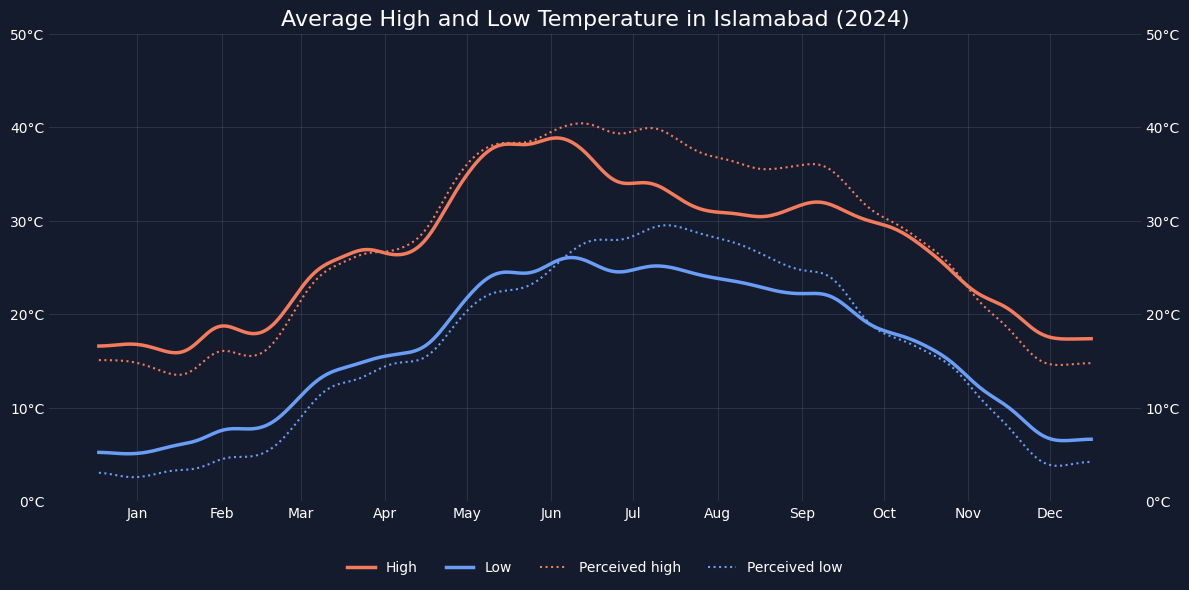

In [13]:
import requests, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from matplotlib.lines import Line2D

# 1. Fetch Data (Islamabad)
url = "https://archive-api.open-meteo.com/v1/archive"
params = {"latitude": 33.68, "longitude": 73.04, "start_date": "2024-01-01", "end_date": "2024-12-30",
          "daily": ["temperature_2m_max", "temperature_2m_min", "apparent_temperature_max", "apparent_temperature_min"], "timezone": "Asia/Karachi"}
df = pd.DataFrame(requests.get(url, params=params).json()["daily"])
df["time"] = pd.to_datetime(df["time"])

# 2. Setup Plot & Smooth Data
fig, ax = plt.subplots(figsize=(12, 6), facecolor='#141b2d')
ax.set_facecolor('#141b2d')
smooth = lambda col: gaussian_filter1d(df[col], sigma=7)
high, low = smooth("temperature_2m_max"), smooth("temperature_2m_min")
p_high, p_low = smooth("apparent_temperature_max"), smooth("apparent_temperature_min")

# 3. Draw Lines & Format
ax.plot(df["time"], high, color='#f47c5c', lw=2.5)
ax.plot(df["time"], low, color='#6a9df6', lw=2.5)
ax.plot(df["time"], p_high, color='#f47c5c', lw=1.5, ls=':')
ax.plot(df["time"], p_low, color='#6a9df6', lw=1.5, ls=':')

yticks = range(0, 55, 10)
ax.set_yticks(yticks); ax.set_yticklabels([f"{t}°C" for t in yticks], color='white')
ax.set_xticks(pd.to_datetime([f'2024-{m:02d}-15' for m in range(1, 13)]))
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], color='white')
ax.tick_params(colors='white', length=0)
ax.grid(color='white', alpha=0.1)
for s in ax.spines.values(): s.set_color('none')

ax2 = ax.twinx(); ax2.set_yticks(yticks); ax2.set_yticklabels([f"{t}°C" for t in yticks], color='white')
ax2.tick_params(colors='white', length=0)
for s in ax2.spines.values(): s.set_color('none')

# 4. Title & Legend
ax.set_title('Average High and Low Temperature in Islamabad (2024)', loc='Center', color='white', fontsize=16)
legend = [Line2D([0], [0], color='#f47c5c', lw=2.5, label='High'),
          Line2D([0], [0], color='#6a9df6', lw=2.5, label='Low'),
          Line2D([0], [0], color='#f47c5c', lw=1.5, ls=':', label='Perceived high'),
          Line2D([0], [0], color='#6a9df6', lw=1.5, ls=':', label='Perceived low')]
ax.legend(handles=legend, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False, labelcolor='white')

plt.tight_layout()

# Save and Download FIRST
plt.savefig('islamabad_chart.png', dpi=300, bbox_inches='tight')
from google.colab import files
files.download('islamabad_chart.png')
# Save to Excel
df.to_excel("islamabad_weather.xlsx", index=False)

# Download it
from google.colab import files
files.download("islamabad_weather.xlsx")